# Auto-Tuning Gray-Scott Using Julia

# 1. Setup

The setup is the same as in the KernelAbstractions tutorial. The cells below activate the project environment, install and load the packages, and select the backend; first set `DEV` below to match your hardware.

In [33]:
# Pick your hardware: :NVIDIA, :AMD, :Metal, or :CPU
DEV = :Metal

:Metal

In [34]:
using Pkg
Pkg.activate(joinpath(@__DIR__))

  Activating project at `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks`


In [35]:
Pkg.add(["BenchmarkTools", "ProgressMeter", "Plots", "ColorTypes", "KernelAbstractions", "PythonCall", "JSON", String(DEV)])
Pkg.develop(path="/Users/fjwillemsen/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/KernelTuner.jl")

     Project No packages added to or removed from `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
    Manifest No packages added to or removed from `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Manifest.toml`
   Resolving package versions...
     Project No packages added to or removed from `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
    Manifest No packages added to or removed from `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Manifest.toml`


In [36]:
using BenchmarkTools, ProgressMeter, Plots, ColorTypes, KernelAbstractions, KernelTuner

In [37]:
Pkg.status()

Status `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
  [6e4b80f9] BenchmarkTools v1.8.0
  [3da002f7] ColorTypes v0.12.5
  [7073ff75] IJulia v1.34.4
  [682c06a0] JSON v1.13.4
  [63c18a36] KernelAbstractions v0.10.4
  [d8e2316b] KernelTuner v1.1.0 `~/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/KernelTuner.jl`
  [dde4c033] Metal v1.12.0
  [91a5bcdd] Plots v1.41.7
  [92933f4c] ProgressMeter v1.13.0
  [6099a3de] PythonCall v0.9.37


In [38]:
if DEV == :NVIDIA
    using CUDA
    ArrayKA = CUDA.CuArray
    Backend = CUDA.CUDABackend()
elseif DEV == :AMD
    using AMDGPU
    ArrayKA = AMDGPU.ROCArray
    Backend = AMDGPU.ROCBackend()
elseif DEV == :Metal
    using Metal
    ArrayKA = Metal.MtlArray
    Backend = Metal.MetalBackend()
elseif DEV == :CPU
    ArrayKA = Array
    Backend = CPU()
    @warn "Using CPU backend. This will be very slow and might not work for all use cases in this tutorial. Consider using a GPU backend."
else
    error("Unknown DEV = $DEV. Use :NVIDIA, :AMD, :Metal, or :CPU.")
end

MetalBackend()

In [39]:
# Define a lightweight text wrapper class to get live stdout to the cell
using PythonCall
sys = pyimport("sys")
@pyexec """
class JuliaTextStdout:
    def __init__(self, jl_print):
        self.jl_print = jl_print
    def write(self, string):
        if string:
            self.jl_print(string)
        return len(string)
    def flush(self):
        pass
""" => JuliaTextStdout
sys.stdout = JuliaTextStdout(print)

# Define a function to get the source of a cell by tag
using JSON
function get_cell_by_tag(tag_name)
    notebook = JSON.parsefile("gray-scott.ipynb")
    cell_idx = findfirst(notebook["cells"]) do cell
        tags = get(get(cell, "metadata", Dict()), "tags", [])
        return tag_name in tags
    end
    if isnothing(cell_idx)
        error("No cell found with tag: $tag_name")
    end
    source = notebook["cells"][cell_idx]["source"]
    return join(source)
end

get_cell_by_tag (generic function with 1 method)

In [40]:
using Plots
using Statistics

function plot_heatmap_tuning_results(data, key_x_axis::String, key_y_axis::String, objective::String="time", higher_is_better=false)

    # Unique sorted values for axes
    data_x_axis = sort(unique([Int(d[key_x_axis]) for d in data]))
    data_y_axis = sort(unique([Int(d[key_y_axis]) for d in data]))

    # Create a matrix for the heatmap
    heatmap_data = Matrix{Float32}(undef, length(data_y_axis), length(data_x_axis))
    fill!(heatmap_data, NaN)  # Fill with NaN to indicate missing values

    for (i, yval) in enumerate(data_y_axis)
        for (j, xval) in enumerate(data_x_axis)
            # Find the entry with this combination
            entry = findfirst(d -> Int(d[key_x_axis]) == xval && Int(d[key_y_axis]) == yval, data)
            if entry !== nothing
                heatmap_data[i, j] = data[entry][objective]
            end
        end
    end

    # Create the heatmap
    heatmap(data_x_axis, data_y_axis, heatmap_data,
        xlabel = titlecase(replace(key_x_axis, "_" => " ")),
        ylabel = titlecase(replace(key_y_axis, "_" => " ")),
        title = "Tuning Heatmap: " * titlecase(replace(objective, "_" => " ")),
        color = higher_is_better ? cgrad(:RdYlGn) : reverse(cgrad(:RdYlGn)),
        colorbar_title = " \n" * titlecase(replace(objective, "_" => " ")) * (higher_is_better ? " (higher is better)" : " (lower is better)"),
        colorbar = true,
        right_margin = 3Plots.mm,
        xticks = (data_x_axis, string.(data_x_axis)),
        yticks = (data_y_axis, string.(data_y_axis)),
        xscale = :log2,
        yscale = :log2,
        # aspect_ratio = 1,
        # size = (700, 600),
        dpi = 300,
        grid = false,
    )

    # Annotate each cell with the value
    for (i, yval) in enumerate(data_y_axis)
        for (j, xval) in enumerate(data_x_axis)
            val = heatmap_data[i, j]
            # Swap text color - in this color scheme, the middle values are yellow, so we want to use black text for those and white text for the extremes
            min_val = minimum(skipmissing(vec(filter(!isnan, vec(heatmap_data)))))
            max_val = maximum(skipmissing(vec(filter(!isnan, vec(heatmap_data)))))
            range_val = max_val - min_val
            text_color = min_val + (range_val * 0.25) < val < min_val + (range_val * 0.75) ? :black : :white
            annotate!(xval, yval, text(round(val, digits=2), 10, text_color, :center))
        end
    end

    display(current())
end

plot_heatmap_tuning_results (generic function with 3 methods)

# 2. The Gray-Scott Reaction-Diffusion Model

The Gray-Scott Reaction-Diffusion model is a mathematical model used to describe how two interacting substances, typically denoted as $U$ and $V$, evolve over time in a spatial domain. This model captures the combined effects of chemical reactions and diffusion, leading to complex pattern formations such as spots, stripes, and waves, which resemble natural phenomena like animal skin patterns or chemical reactions in a petri dish. 

## The Kernel

This kernel is a relatively simple one; for more information on this implementation see [the KernelAbstractions tutorial](). We'll start by adding the workgroup size as tunable parameters. For this, use Julia's `::Val{} where` syntax. This compiles to a constant and a default can be provided so your kernel is still completely executable outside of autotuning contexts.


In [41]:
using KernelAbstractions

# 5-point Laplacian, same as the reference CPU implementation
@inline function laplacian(A, x, y, dx)
    @inbounds DAx = (A[x-1, y] - (2 * A[x, y]) + A[x+1, y]) / dx
    @inbounds DAy = (A[x, y-1] - (2 * A[x, y]) + A[x, y+1]) / dx
    return DAx + DAy
end

# BX × BY is the workgroup size: Kernel Tuner passes each tunable parameter to the kernel as a `Val` argument
@kernel function gs_gpu_kernel!(Uout, Vout, @Const(U), @Const(V), D_u, D_v, F, k, dt, dx, nx, ny, noise,
        ::Val{BX} = Val(16), ::Val{BY} = Val(16)) where {BX, BY}
    x, y = @index(Global, NTuple)

    if (1 < x < nx) && (1 < y < ny)
        u = @inbounds U[x, y]
        v = @inbounds V[x, y]

        ΔU = laplacian(U, x, y, dx)
        ΔV = laplacian(V, x, y, dx)
        UVV = u * v * v
        Nr = noise == 0 ? zero(u) : noise * randn(Float32)
        DU = D_u * ΔU - UVV + F * (1 - u) + Nr
        DV = D_v * ΔV + UVV - (F + k) * v
        newU = u + DU * dt
        newV = v + DV * dt

        @inbounds Uout[x, y] = newU
        @inbounds Vout[x, y] = newV
    end
end

Now that we have our kernel source code, it might be nice to see what it actually does. Don't worry about the implementation details of the cell below, they're just to draw a nice animation. 


In [42]:
function simulate_gs_gpu(n = 500 #=Grid size=#, nsteps = 10000 #=Number of iterations=# ;
                        init_multi = 0.5,
                        noise = 0.0f0,
                        D_u = 0.16f0,
                        D_v = 0.08f0,
                        F = 0.035f0,
                        k = 0.06f0,
                        dt = 1.0f0,
                        dx = 1.0f0,
                        plot_every = 500)

    U = Float32.(rand(0.0:0.001:0.1, n, n))
    V = zeros(Float32, n, n)

    n_mid = div(n, 2)
    U[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(init_multi)
    V[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(0.5 * init_multi)

    U1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    U2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    KernelAbstractions.copyto!(Backend, U1, U)
    KernelAbstractions.copyto!(Backend, V1, V)
    KernelAbstractions.copyto!(Backend, U2, U)
    KernelAbstractions.copyto!(Backend, V2, V)

    kernel = gs_gpu_kernel!(Backend, (cld(n, 16), cld(n, 16)))
    readU, readV, writeU, writeV = U1, V1, U2, V2

    prog = Progress(div(nsteps, plot_every))
    plt = Plots.plot(title="Gray-Scott Model", xlabel="X", ylabel="Y")

    anim = Plots.@animate for t in 1:div(nsteps, plot_every)
        for _ in 1:plot_every
            kernel(writeU, writeV, readU, readV, D_u, D_v, F, k, dt, dx, n, n, noise, ndrange=(n, n))
            readU, readV, writeU, writeV = writeU, writeV, readU, readV
        end

        KernelAbstractions.copyto!(Backend, U, readU)
        KernelAbstractions.synchronize(Backend)

        next!(prog)
        Plots.heatmap!(plt, U, color=cgrad([:black, :blue, :white]), clims=extrema(U), title="Gray-Scott Model")
    end
    gif(anim, "gs_ka.gif"; fps=10)
end

simulate_gs_gpu (generic function with 3 methods)

Let's see our Gray-Scott Model in action:

Progress: 100%|█████████████████████████████████████████| Time: 0:00:15


 16.882090 seconds (388.70 M allocations: 12.513 GiB, 8.06% gc time, 0.11% compilation time: 88% of which was recompilation)


[ Info: Saved animation to /Users/fjwillemsen/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/gs_ka.gif


Plots.AnimatedGif("/Users/fjwillemsen/University/Research/Projects/Bayesian_Optimization_in_Kernel_Tuner/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/gs_ka.gif")
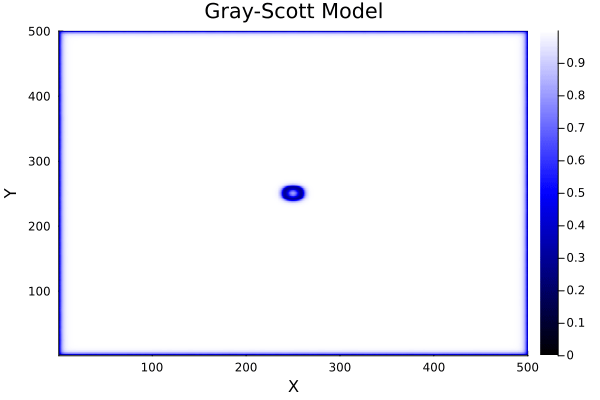

In [43]:
@time simulate_gs_gpu(500, 10000)

# Autotuning the Kernel

We can see the kernel works. But can we improve its performance? Let's tune the workgroup sizes we added earlier and find out.
Now that we have our kernel source code in a file, we can get started on the autotuning! We start by generating some input data that we will use to run our GPU kernel.

In [44]:
# parameters
n = 500
init_multi = 0.5

U = Float32.(rand(0.0:0.001:0.1, n, n))
V = zeros(Float32, n, n)

n_mid = div(n, 2)
U[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(1.0 * init_multi)
V[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(0.5 * init_multi)

U1 = KernelAbstractions.allocate(Backend, Float32, n, n)
V1 = KernelAbstractions.allocate(Backend, Float32, n, n)
U2 = KernelAbstractions.allocate(Backend, Float32, n, n)
V2 = KernelAbstractions.allocate(Backend, Float32, n, n)
KernelAbstractions.copyto!(Backend, U1, U)
KernelAbstractions.copyto!(Backend, V1, V)
KernelAbstractions.copyto!(Backend, U2, U)
KernelAbstractions.copyto!(Backend, V2, V)

500×500 MtlMatrix{Float32, Metal.SharedStorage}:
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0 

## Step 2.1: tuning the workgroup size

We start with the simple kernel `gs_gpu_kernel!`, where every work-item computes exactly one grid point. The only thing we can tune here is the **workgroup size**: how many work-items are grouped together, and in what shape (`block_size_x` × `block_size_y`).

Kernel Tuner uses `block_size_x` and `block_size_y` as the workgroup dimensions by default, and by default divides the problem size by them to get the number of workgroups, so we don't need to specify `grid_div_x`/`grid_div_y` here.

In [45]:
using KernelTuner

arguments = [U1, V1, U2, V2, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0]
tune_params = [
    ("block_size_x", [8, 16, 32, 64, 128]),  # workgroup size along x
    ("block_size_y", [1, 2, 4, 8, 16]),      # workgroup size along y
]

results_wg, env_wg = KernelTuner.tune_kernel(
    "gs_gpu_kernel!",
    get_cell_by_tag("gs_gpu_kernel"),   # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
    (n, n),
    arguments,
    tune_params,
    # each workgroup covers (block_size_x) × (block_size_y) grid points
    grid_div_x=("block_size_x", 1), grid_div_y=("block_size_y", 1),
    lang="Julia",
    verbose=true,
)

best_wg = (Int(env_wg["best_config"]["block_size_x"]), Int(env_wg["best_config"]["block_size_y"]))

Using: Apple M5 Pro
Searchspace has 24 configurations after restrictions.
block_size_x=8, block_size_y=1, time=0.609ms
block_size_x=8, block_size_y=2, time=0.515ms
block_size_x=8, block_size_y=4, time=0.448ms
block_size_x=8, block_size_y=8, time=0.411ms
block_size_x=8, block_size_y=16, time=0.407ms
block_size_x=16, block_size_y=1, time=0.313ms
block_size_x=16, block_size_y=2, time=0.497ms
block_size_x=16, block_size_y=4, time=0.342ms
block_size_x=16, block_size_y=8, time=0.503ms
block_size_x=16, block_size_y=16, time=0.514ms
block_size_x=32, block_size_y=1, time=0.431ms
block_size_x=32, block_size_y=2, time=0.341ms
block_size_x=32, block_size_y=4, time=0.516ms
block_size_x=32, block_size_y=8, time=0.346ms
block_size_x=32, block_size_y=16, time=0.366ms
block_size_x=64, block_size_y=1, time=0.288ms
block_size_x=64, block_size_y=2, time=0.497ms
block_size_x=64, block_size_y=4, time=0.283ms
block_size_x=64, block_size_y=8, time=0.256ms
block_size_x=64, block_size_y=16, time=7.316ms
block_s

(64, 8)

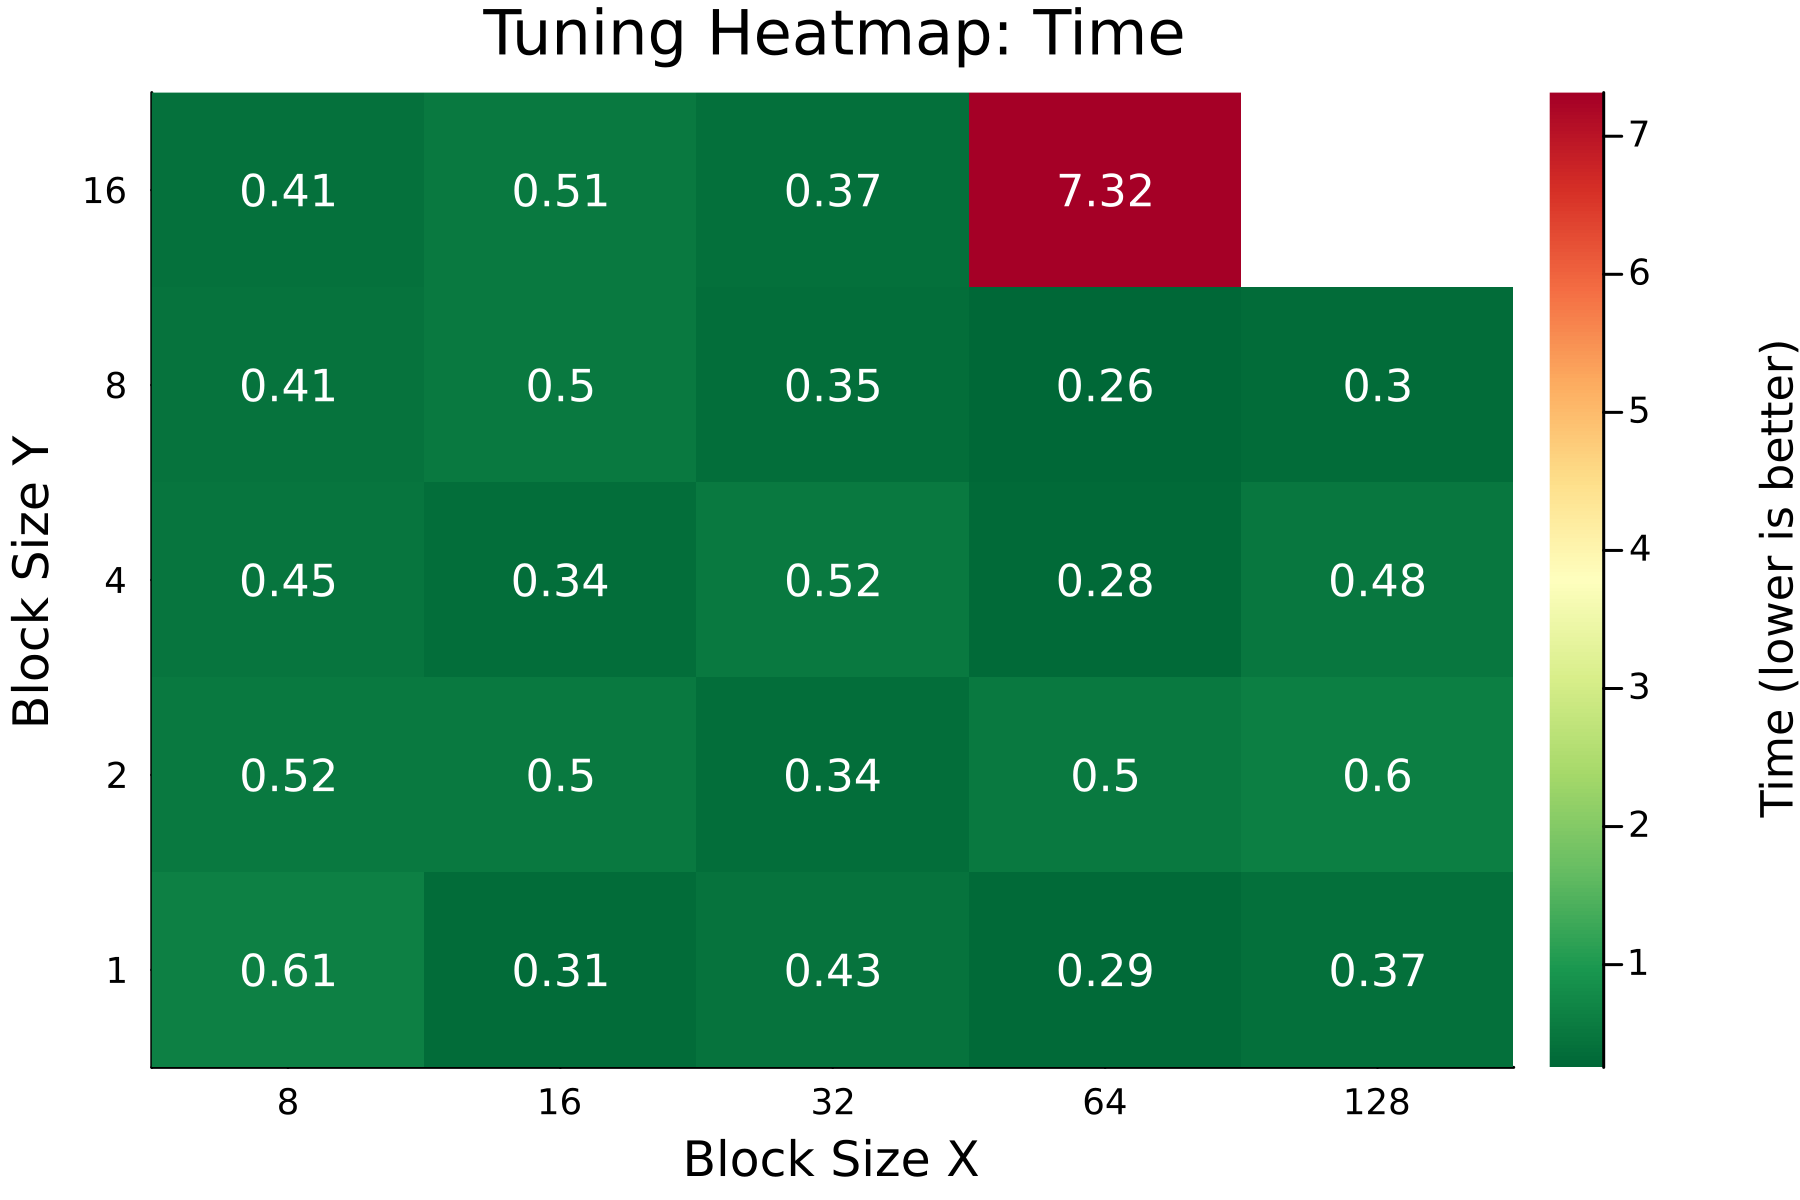

In [46]:
plot_heatmap_tuning_results(results_wg, "block_size_x", "block_size_y")

We can use the heatmap to analyze potentially interesting regions. 
What's going on with the missing configuration for `(128, 16)`? By default, Kernel Tuner applies a restriction that the product of the block sizes can not exceed 1024 as this is a hard limit for GPU programming models. We'll find out more about restrictions later on. 

## Step 2: tuning the tile size

Of course we can do more than just tuning the workgroup sizes. Tiling, for example: a more advanced implementation that gives each work item a `P` × `Q` tile of the grid (`P` along `y`, `Q` along `x`). 
This is implemented in kernel `gs_gpu_kernel_tuned!`, where each work-item computes a `Q` × `P` tile of grid points. Each workgroup now covers `(block_size_x * Q) × (block_size_y * P)` grid points, so we tell Kernel Tuner to divide the problem size by both with `grid_div_x` and `grid_div_y`. 
The kernel also receives the workgroup size `BX` × `BY` as compile-time parameters: Kernel Tuner passes every tunable parameter to a Julia kernel as a `Val` argument, in the order they are defined, so the signature needs a slot for each of them (even though the workgroup size itself is set at launch).

In [47]:
using KernelAbstractions

# Fill per-work-item halo cache tile[q, p] = A[x1+q-2, y1+p-2] (out-of-bounds → zero).
# tile is `@private Float32 (Q + 2, P + 2)` — compile-time size from kernel parameters P, Q.
@inline function load_tile!(tile, A, x1, y1, nx, ny, ::Val{P}, ::Val{Q}) where {P, Q}
    @inbounds for q in 1:(Q + 2), p in 1:(P + 2)
        x = x1 + q - 2
        y = y1 + p - 2
        if 1 <= x <= nx && 1 <= y <= ny
            tile[q, p] = A[x, y]
        else
            tile[q, p] = zero(eltype(A))
        end
    end
    return
end

# Laplacian at tile indices (q, p) in 1:Q, 1:P — same 5-point formula as the CPU reference.
@inline function laplacian_tile(tile, q, p, dx)
    u = tile[q + 1, p + 1]
    @inbounds ux_m = tile[q, p + 1]
    @inbounds ux_p = tile[q + 2, p + 1]
    @inbounds uy_m = tile[q + 1, p]
    @inbounds uy_p = tile[q + 1, p + 2]
    ((ux_m - 2 * u + ux_p) + (uy_m - 2 * u + uy_p)) / dx
end

@kernel function gs_gpu_kernel_tiled!(Uout, Vout, @Const(U), @Const(V),
        D_u, D_v, F, k, dt, dx, nx, ny, noise, ::Val{P}, ::Val{Q}, ::Val{BX}, ::Val{BY}) where {P, Q, BX, BY}
    # Section 1: get indices
    i, j = @index(Global, NTuple)
    x1 = (i - 1) * Q + 1
    y1 = (j - 1) * P + 1

    # Section 2: allocate register memory and get data
    tileU = @private Float32 (Q + 2, P + 2)
    tileV = @private Float32 (Q + 2, P + 2)
    stepU = @private Float32 (Q, P)
    stepV = @private Float32 (Q, P)

    if (x1 < nx) && (x1 + Q > 2)
        load_tile!(tileU, U, x1, y1, nx, ny, Val(P), Val(Q))
        load_tile!(tileV, V, x1, y1, nx, ny, Val(P), Val(Q))

        # Section 3: calculate Laplacians (values → private step tile)
        for q in 1:Q, p in 1:P
            if (1 < x1 + q - 1 < nx) && (1 <  y1 + p - 1 < ny)
                u = tileU[q + 1, p + 1]
                v = tileV[q + 1, p + 1]
                ΔU = laplacian_tile(tileU, q, p, dx)
                ΔV = laplacian_tile(tileV, q, p, dx)
                UVV = u * v * v
                Nr = noise == 0 ? zero(u) : noise * randn(Float32)
                DU = D_u * ΔU - UVV + F * (1 - u) + Nr
                DV = D_v * ΔV + UVV - (F + k) * v
                stepU[q, p] = u + DU * dt
                stepV[q, p] = v + DV * dt
            end
        end

        # Section 4: global writes
        for q in 1:Q, p in 1:P
            x = x1 + q - 1
            y = y1 + p - 1
            if (1 < x < nx) && (1 < y < ny)
                @inbounds Uout[x, y] = stepU[q, p]
                @inbounds Vout[x, y] = stepV[q, p]
            end
        end
    end
end

Next, we tune only the tile size `P` × `Q`, keeping the best workgroup size we found in step 1 fixed:

In [48]:
using KernelTuner

arguments = [U1, V1, U2, V2, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0]
tune_params = [
    ("P", [1, 2, 4, 8, 16]),                    # tile size per work-item along y
    ("Q", [1, 2, 4, 8, 16]),                    # tile size per work-item along x
    ("block_size_x", [best_wg[1]]),             # keep the best workgroup size from step 1 fixed
    ("block_size_y", [best_wg[2]]),
]

results_ti, env = KernelTuner.tune_kernel(
    "gs_gpu_kernel_tiled!",
    get_cell_by_tag("gs_gpu_kernel_tiled"), # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
    (n, n),
    arguments,
    tune_params,
    # each workgroup covers (block_size_x * Q) × (block_size_y * P) grid points
    grid_div_x=("block_size_x", "Q"), grid_div_y=("block_size_y", "P"),
    lang="Julia",
    verbose=true
)

display(results_ti)

Using: Apple M5 Pro
Searchspace has 25 configurations after restrictions.
P=1, Q=1, block_size_x=64, block_size_y=8, time=0.447ms
P=1, Q=2, block_size_x=64, block_size_y=8, time=0.341ms
P=1, Q=4, block_size_x=64, block_size_y=8, time=0.474ms
P=1, Q=8, block_size_x=64, block_size_y=8, time=0.439ms
P=1, Q=16, block_size_x=64, block_size_y=8, time=0.624ms
P=2, Q=1, block_size_x=64, block_size_y=8, time=0.598ms
P=2, Q=2, block_size_x=64, block_size_y=8, time=0.367ms
P=2, Q=4, block_size_x=64, block_size_y=8, time=0.415ms
P=2, Q=8, block_size_x=64, block_size_y=8, time=0.478ms
P=2, Q=16, block_size_x=64, block_size_y=8, time=0.560ms
P=4, Q=1, block_size_x=64, block_size_y=8, time=0.370ms
P=4, Q=2, block_size_x=64, block_size_y=8, time=0.471ms
P=4, Q=4, block_size_x=64, block_size_y=8, time=0.532ms
P=4, Q=8, block_size_x=64, block_size_y=8, time=0.434ms
P=4, Q=16, block_size_x=64, block_size_y=8, time=0.583ms
P=8, Q=1, block_size_x=64, block_size_y=8, time=0.337ms
P=8, Q=2, block_size_x=64, 

25-element Vector{Dict}:
 Dict{String, Any}("strategy_time" => 0.0, "Q" => 1.0, "timestamp" => "2026-11-05 19:44:41.539711+00:00", "time" => 0.44731972023519373, "block_size_x" => 64.0, "times" => Any[0.322708, 0.314417, 0.2915836466295719, 0.9743757048372328, 0.3140416466295719, 0.518208323314786, 0.271292], "compile_time" => 6.773333007004112, "verification_time" => 0, "framework_time" => 16.808028519114764, "P" => 1.0…)
 Dict{String, Any}("strategy_time" => 0.0, "Q" => 2.0, "timestamp" => "2026-11-05 19:44:41.686711+00:00", "time" => 0.3414374996827294, "block_size_x" => 64.0, "times" => Any[0.577041, 0.5174587048372328, 0.516542, 0.265625, 0.2509166466295719, 0.2549996466295719, 0.243083], "compile_time" => 7.065750018227845, "verification_time" => 0, "framework_time" => 16.808028519114764, "P" => 1.0…)
 Dict{String, Any}("strategy_time" => 0.0, "Q" => 4.0, "timestamp" => "2026-11-05 19:44:41.828046+00:00", "time" => 0.47398650000000003, "block_size_x" => 64.0, "times" => Any[0.494

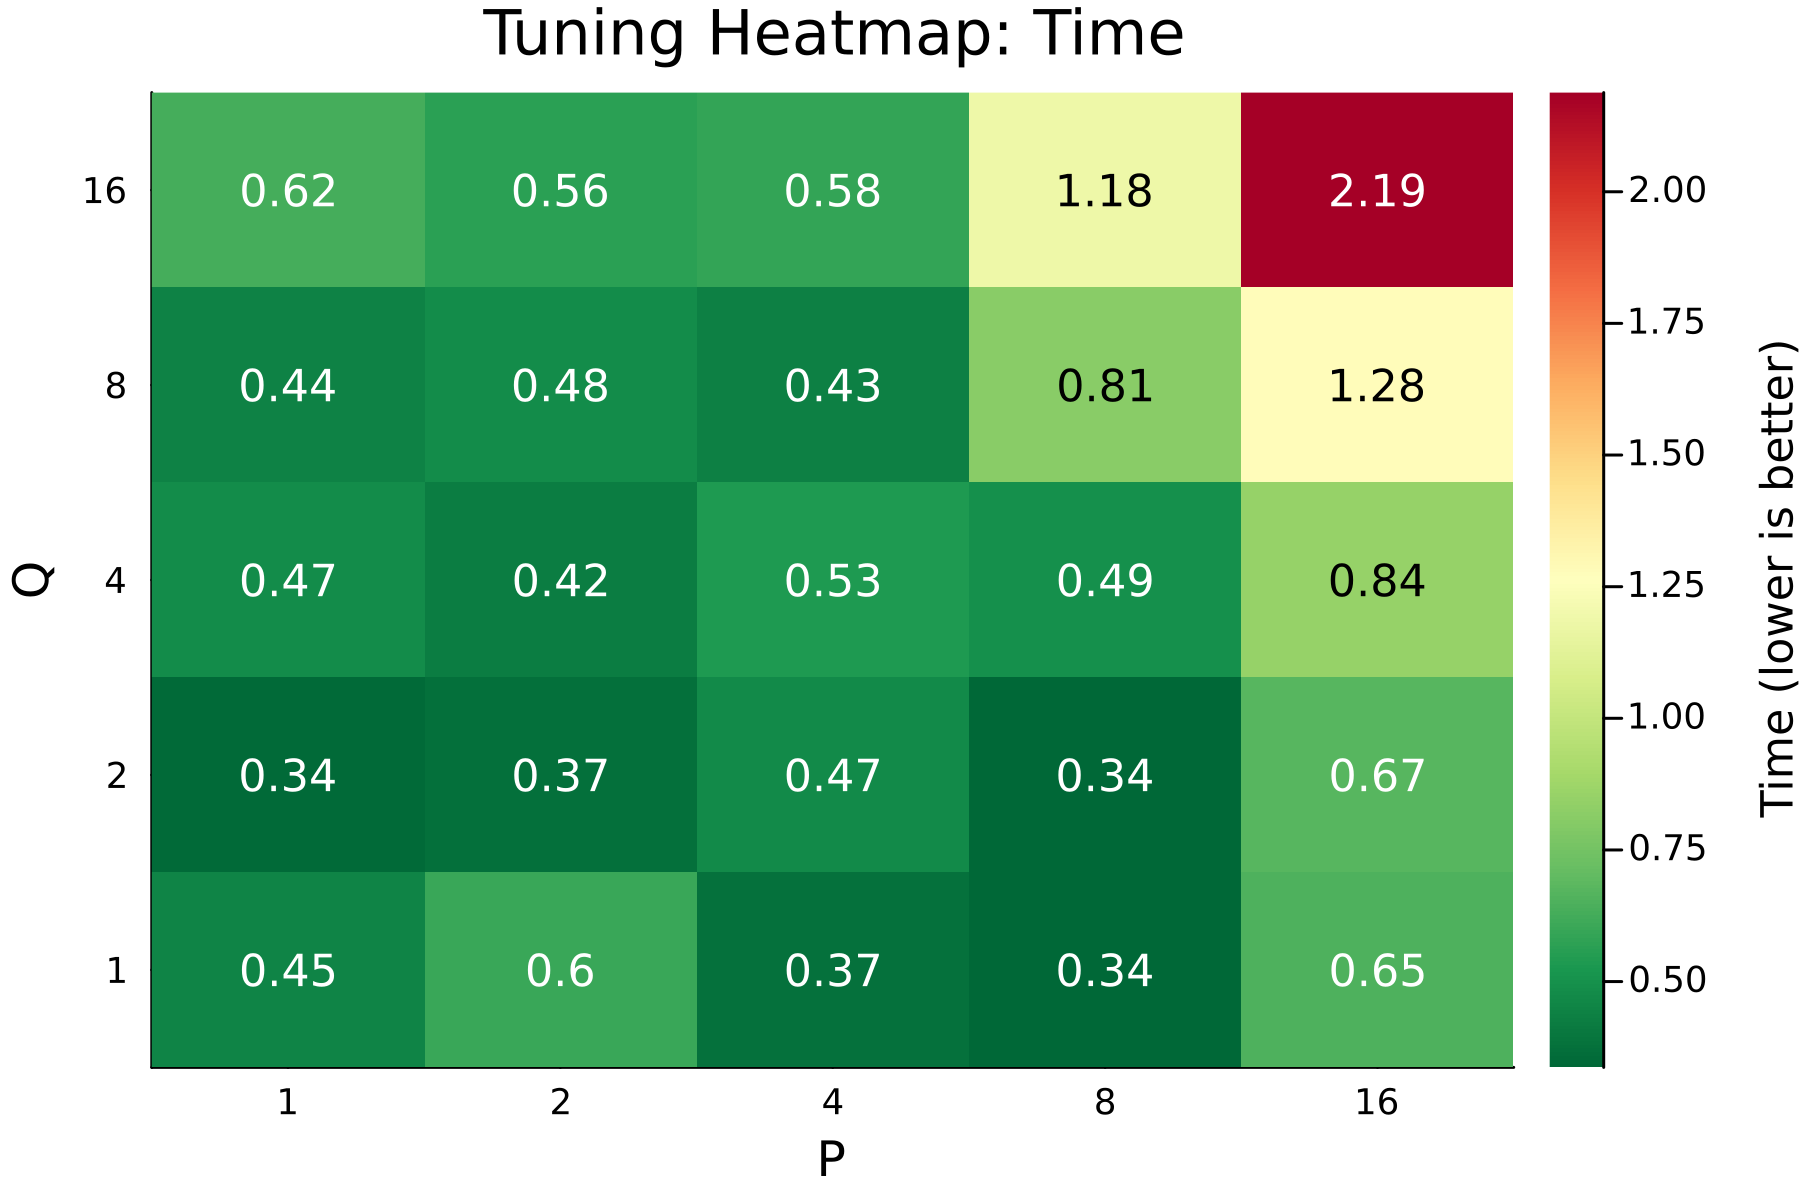

In [49]:
plot_heatmap_tuning_results(results_ti, "P", "Q")

# 3. Additional Tuning options

## Step 3.1: tuning tile size and workgroup size together

The best tile size may depend on the workgroup size and vice versa, so finally we tune both at the same time. Note how much larger the search space becomes. To reduce configurations that would not work (either because they can not compile or are always going to be slow), we can use Kernel Tuner's `restriction` setting. This takes a list of strings of expressions. Only configurations that meet all the restriction conditions are left in the searchspace. Let's define a restriction for the product of the block sizes. 

Because the searchspace is getting larger, it might be convenient to save the results in a file, which also allows us to pick up where we left in case the tuning is interrupted. We can pass the `cache` argument with a filename of our choice.

In [50]:
using KernelTuner

arguments = [U1, V1, U2, V2, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0]
tune_params = [
    ("P", [1, 2, 4, 8, 16]),                    # tile size per work-item along y
    ("Q", [1, 2, 4, 8, 16]),                    # tile size per work-item along x
    ("block_size_x", [8, 16, 32, 64, 128]),     # workgroup size along x
    ("block_size_y", [1, 2, 4, 8, 16]),         # workgroup size along y
]

# keep workgroups between one SIMD-group (32) and the hardware maximum (1024 work-items)
restrictions = ["32 <= block_size_x * block_size_y <= 1024"]

results, env = KernelTuner.tune_kernel(
    "gs_gpu_kernel_tiled!",
    get_cell_by_tag("gs_gpu_kernel_tiled"), # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
    (n, n),
    arguments,
    tune_params,
    restrictions=restrictions,
    # each workgroup covers (block_size_x * Q) × (block_size_y * P) grid points
    grid_div_x=("block_size_x", "Q"), grid_div_y=("block_size_y", "P"),
    lang="Julia",
    verbose=true
)

display(results)

Using: Apple M5 Pro
Searchspace has 525 configurations after restrictions.
P=1, Q=1, block_size_x=8, block_size_y=4, time=0.445ms
P=1, Q=1, block_size_x=8, block_size_y=8, time=0.498ms
P=1, Q=1, block_size_x=8, block_size_y=16, time=0.452ms
P=1, Q=1, block_size_x=16, block_size_y=2, time=0.642ms
P=1, Q=1, block_size_x=16, block_size_y=4, time=0.420ms
P=1, Q=1, block_size_x=16, block_size_y=8, time=0.677ms
P=1, Q=1, block_size_x=16, block_size_y=16, time=0.578ms
P=1, Q=1, block_size_x=32, block_size_y=1, time=0.388ms
P=1, Q=1, block_size_x=32, block_size_y=2, time=0.461ms
P=1, Q=1, block_size_x=32, block_size_y=4, time=0.537ms
P=1, Q=1, block_size_x=32, block_size_y=8, time=0.570ms
P=1, Q=1, block_size_x=32, block_size_y=16, time=0.453ms
P=1, Q=1, block_size_x=64, block_size_y=1, time=0.630ms
P=1, Q=1, block_size_x=64, block_size_y=2, time=0.465ms
P=1, Q=1, block_size_x=64, block_size_y=4, time=0.587ms
P=1, Q=1, block_size_x=64, block_size_y=8, time=0.582ms
P=1, Q=1, block_size_x=64, bl

525-element Vector{Dict}:
 Dict{String, Any}("strategy_time" => 0.0, "Q" => 1.0, "timestamp" => "2026-11-05 19:44:46.853694+00:00", "time" => 0.4449928283240596, "block_size_x" => 8.0, "times" => Any[0.5882916466295719, 0.6275416466295719, 0.5235, 0.645291, 0.292208, 0.283875, 0.29754132331478594], "compile_time" => 6.552415958140045, "verification_time" => 0, "framework_time" => 1.0287960230647557, "P" => 1.0…)
 Dict{String, Any}("strategy_time" => 0.0, "Q" => 1.0, "timestamp" => "2026-11-05 19:44:46.990414+00:00", "time" => 0.49831244579693174, "block_size_x" => 8.0, "times" => Any[0.309791, 0.295542, 0.313916, 1.3819579699443578, 0.348958, 0.3246667048372328, 0.324834], "compile_time" => 6.048125040251762, "verification_time" => 0, "framework_time" => 1.0287960230647557, "P" => 1.0…)
 Dict{String, Any}("strategy_time" => 0.0, "Q" => 1.0, "timestamp" => "2026-11-05 19:44:47.122243+00:00", "time" => 0.4521179949907263, "block_size_x" => 8.0, "times" => Any[0.306916, 0.287583323314786,